# PRCP-1001: Rice Leaf Disease Detection

## Problem Statement

1. Prepare a complete data analysis report on the given data.
2. Create a model which can classify the three major attacking diseases of rice plants: leaf smut, bacterial leaf blight, and brown spot.
3. Analyze various techniques like data augmentation and create a report on that.
4. Model comparison report stating the performance of multiple models and the best model for production.
5. Report on challenges faced on the data and techniques used, with proper reasoning.

## Objective

Build an image classifier that distinguishes between three rice leaf diseases from photographs, given an unusually small dataset (only ~40 images per class), and identify the modeling and data-augmentation techniques best suited to that constraint.

## Dataset Description

- 120 JPG images of disease-infected rice leaves (119 found in practice), grouped into 3 classes with roughly 40 images each:
  - Bacterial leaf blight
  - Brown spot
  - Leaf smut
- Images are close-up photographs of individual leaf blades, with highly inconsistent raw pixel dimensions (no two images share the same size).
- Delivered as a nested zip archive: one outer zip containing three per-class zip files.

## Setup: Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## Data Loading

In [2]:
import os
os.listdir('/content/drive/MyDrive/Rice_Leaf_Pred')

['PRCP-1001-RiceLeaf.zip']

### Extracting the Dataset

The dataset arrives as a nested zip structure: the outer zip contains one zip file per disease class, which must be extracted separately.

In [3]:
import zipfile
with zipfile.ZipFile('/content/drive/MyDrive/Rice_Leaf_Pred/PRCP-1001-RiceLeaf.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/rice_leaf_data')

In [4]:
import zipfile
import os

nested_dir = '/content/rice_leaf_data/Data'
for filename in os.listdir(nested_dir):
    if filename.endswith('.zip'):
        filepath = os.path.join(nested_dir, filename)
        with zipfile.ZipFile(filepath, 'r') as zip_ref:
            zip_ref.extractall(nested_dir)

In [5]:
for root, dirs, files in os.walk('/content/rice_leaf_data/Data'):
    print(root, '->', len(files), 'files')

/content/rice_leaf_data/Data -> 3 files
/content/rice_leaf_data/Data/Brown spot -> 40 files
/content/rice_leaf_data/Data/Bacterial leaf blight -> 40 files
/content/rice_leaf_data/Data/Leaf smut -> 39 files


## Exploratory Data Analysis

### Identifying Class Folders

In [6]:
data_dir = '/content/rice_leaf_data/Data'


In [7]:
classes = [c for c in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, c))]
print(classes)

['Brown spot', 'Bacterial leaf blight', 'Leaf smut']


### Sample Image Properties

In [8]:
from PIL import Image
import os
for cls in classes:
    cls_path = os.path.join(data_dir, cls)
    sample_file = os.listdir(cls_path)[0]
    img = Image.open(os.path.join(cls_path, sample_file))
    print(cls, '-> size:', img.size, ', mode:', img.mode)

Brown spot -> size: (1530, 371) , mode: RGB
Bacterial leaf blight -> size: (3081, 897) , mode: RGB
Leaf smut -> size: (565, 233) , mode: RGB


### Checking Image Size Consistency Across the Full Dataset

In [9]:
sizes = []
for cls in classes:
    cls_path = os.path.join(data_dir, cls)
    for fname in os.listdir(cls_path):
        img = Image.open(os.path.join(cls_path, fname))
        sizes.append((cls, fname, img.size))

import pandas as pd
sizes_df = pd.DataFrame(sizes, columns=['class', 'filename', 'size'])
sizes_df['size'].value_counts()

,count
size,
"(3081, 897)",85
"(250, 200)",2
"(1530, 371)",1
"(286, 92)",1
"(296, 88)",1
"(699, 197)",1
"(467, 104)",1
"(311, 170)",1
"(427, 193)",1


### Viewing Sample Images from Each Class

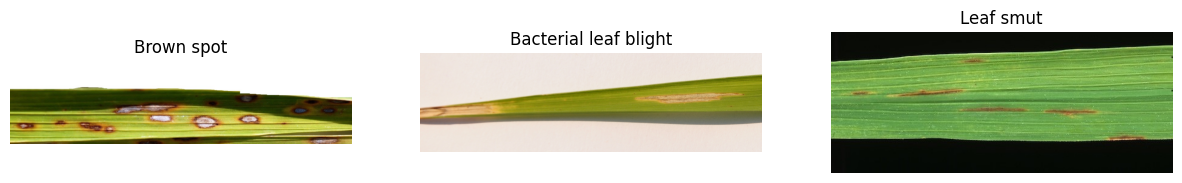

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, cls in enumerate(classes):
    cls_path = os.path.join(data_dir, cls)
    sample_file = os.listdir(cls_path)[0]
    img = Image.open(os.path.join(cls_path, sample_file))
    axes[i].imshow(img)
    axes[i].set_title(cls)
    axes[i].axis('off')
plt.show()

## Data Augmentation & Data Loading Pipeline

Given only ~96 training images after the split, augmentation is essential to reduce overfitting. Hue/color-shifting transforms are deliberately excluded, since leaf/lesion color is diagnostically important (see the Augmentation Techniques report below).

In [11]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    zoom_range=0.2,
    brightness_range=[0.8, 1.2],
    validation_split=0.2
)

In [12]:
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    data_dir,
    target_size=(224, 224),
    batch_size=8,
    class_mode='categorical',
    subset='training',
    seed=42
)

val_generator = val_datagen.flow_from_directory(
    data_dir,
    target_size=(224, 224),
    batch_size=8,
    class_mode='categorical',
    subset='validation',
    seed=42
)

Found 96 images belonging to 3 classes.
Found 23 images belonging to 3 classes.


## Model 1: Simple CNN (Trained from Scratch)

Uses `GlobalAveragePooling2D` rather than `Flatten` to keep the parameter count appropriate for this dataset's size (an initial `Flatten`-based version produced 11.17M parameters against only 96 training images — see Challenges report).

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout, Input

model = Sequential([
    Input(shape=(224, 224, 3)),
    Conv2D(32, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    GlobalAveragePooling2D(),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dense(3, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

### Training the Simple CNN

In [14]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=30
)

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 355ms/step - accuracy: 0.3438 - loss: 1.1117 - val_accuracy: 0.3478 - val_loss: 1.1006
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 216ms/step - accuracy: 0.3438 - loss: 1.0892 - val_accuracy: 0.3478 - val_loss: 1.0931
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step - accuracy: 0.3646 - loss: 1.1002 - val_accuracy: 0.3043 - val_loss: 1.0944
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 351ms/step - accuracy: 0.3021 - loss: 1.1191 - val_accuracy: 0.3043 - val_loss: 1.0957
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 244ms/step - accuracy: 0.3438 - loss: 1.0989 - val_accuracy: 0.3478 - val_loss: 1.0831
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 216ms/step - accuracy: 0.3229 - loss: 1.0995 - val_accuracy: 0.3043 - val_loss: 1.0977
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 217ms/step - accuracy: 0.4583 - loss: 1.0805 - val_accuracy: 0.3043 - val_loss: 1.0790
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step - accuracy: 0.4062 - loss: 1.0760 - val_accuracy: 0

### Training Curves

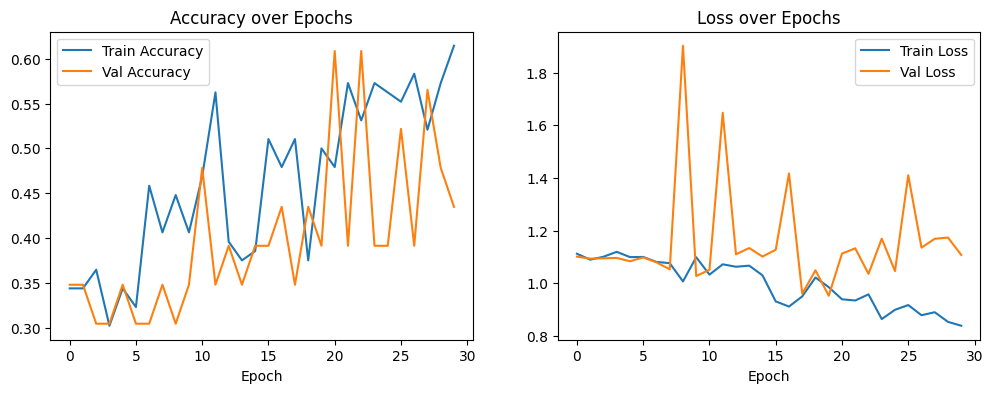

In [15]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.legend()

plt.show()

## Model 2: Transfer Learning (MobileNetV2)

Uses a MobileNetV2 base pretrained on ImageNet, with its convolutional layers frozen, and a small trainable classifier head added on top.

In [16]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
output = Dense(3, activation='softmax')(x)

transfer_model = Model(inputs=base_model.input, outputs=output)
transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,340,163 (8.93 MB)

 Trainable params: 82,179 (321.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Training the Transfer Learning Model

In [17]:
transfer_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

transfer_history = transfer_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20
)

Epoch 1/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.3750 - loss: 1.2586 - val_accuracy: 0.6087 - val_loss: 0.7409
Epoch 2/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 211ms/step - accuracy: 0.5521 - loss: 0.9255 - val_accuracy: 0.7391 - val_loss: 0.5278
Epoch 3/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 239ms/step - accuracy: 0.7292 - loss: 0.5903 - val_accuracy: 0.9130 - val_loss: 0.4022
Epoch 4/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 5s 216ms/step - accuracy: 0.8021 - loss: 0.4253 - val_accuracy: 0.9130 - val_loss: 0.3383
Epoch 5/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 215ms/step - accuracy: 0.8125 - loss: 0.4984 - val_accuracy: 0.9130 - val_loss: 0.2269
Epoch 6/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 215ms/step - accuracy: 0.8438 - loss: 0.3501 - val_accuracy: 0.9130 - val_loss: 0.2213
Epoch 7/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 687ms/step - accuracy: 0.8542 - loss: 0.3218 - val_accuracy: 0.8696 - val_loss: 0.2588
Epoch 8/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 335ms/step - accuracy: 0.9271 - loss: 0.2497 - val_accuracy: 0.86

## Model Evaluation: Confusion Matrix & Classification Report

Uses a dedicated, non-shuffled evaluation generator (`shuffle=False`) to ensure predictions align correctly with true labels — see Challenges report for why this matters.

Found 23 images belonging to 3 classes.
3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step


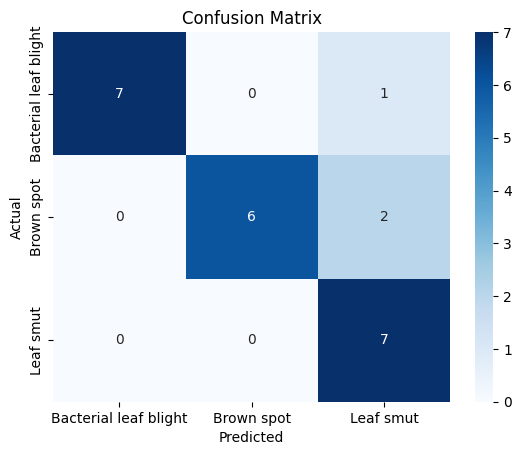

                       precision    recall  f1-score   support

Bacterial leaf blight       1.00      0.88      0.93         8
           Brown spot       1.00      0.75      0.86         8
            Leaf smut       0.70      1.00      0.82         7

             accuracy                           0.87        23
            macro avg       0.90      0.88      0.87        23
         weighted avg       0.91      0.87      0.87        23



In [18]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns

eval_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

eval_generator = eval_datagen.flow_from_directory(
    data_dir,
    target_size=(224, 224),
    batch_size=8,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42
)

y_true = eval_generator.classes
y_pred_probs = transfer_model.predict(eval_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

class_labels = list(eval_generator.class_indices.keys())

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_labels, yticklabels=class_labels, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_labels))

## Reports

### EDA Report

**Dataset Overview**
- 119 total images across 3 rice leaf disease classes: Bacterial leaf blight (40), Brown spot (40), Leaf smut (39) — a near-perfectly balanced but very small dataset.
- All images are RGB, close-up photographs of individual rice leaf blades, taken from varying distances/crops.

**Data Quality Findings**
- Raw image dimensions were highly inconsistent — nearly every image had a unique pixel size (ranging from small crops like 296x88 to larger ones like 1200x900), with no two images sharing dimensions. This reflects inconsistent photography/cropping across the original dataset rather than a processing error.
- Visual inspection confirmed all three classes show the same general subject (an elongated leaf blade against a plain background), with disease identified by the color/pattern of lesions along the leaf — Leaf smut shows dark streaking, Bacterial leaf blight shows pale/yellow patches, Brown spot shows small discrete brown spots.
- Given the inconsistent sizing, all images were resized to a fixed 224x224 for CNN input, accepting minor aspect-ratio distortion as a standard, defensible tradeoff.

**Class Balance**
Classes are nearly perfectly balanced (40/40/39), unlike both prior tabular projects — no class-imbalance handling was required for this dataset.

**Key Implication for Modeling**
With only ~40 images per class, the central challenge of this project is not feature engineering (as in the tabular projects) but working around limited data: aggressive data augmentation and transfer learning from a pretrained model were both necessary, not optional, choices.

### Report on Data Augmentation Techniques

Given only ~96 training images after the train/validation split, data augmentation was essential to reduce overfitting and give the model varied examples to learn from.

**Techniques used (via Keras `ImageDataGenerator`):**
- **Rotation (±30°)** — accounts for leaves photographed at different angles.
- **Width/height shift (±20%)** — accounts for inconsistent cropping/framing observed during EDA.
- **Horizontal and vertical flip** — a flipped leaf is still a structurally valid leaf; disease characteristics are unaffected by orientation.
- **Zoom (±20%)** — further compensates for the wide variation in original image crop/zoom level found during EDA.
- **Brightness range (0.8–1.2×)** — accounts for differing lighting/camera conditions across source photos, kept mild to avoid washing out diagnostic detail.
- **Rescaling (1/255)** — normalizes pixel values to the 0-1 range for stable neural network training.

**Techniques deliberately excluded:**
- **Hue/color-shifting augmentation** was deliberately not used. All three diseases are partly distinguished by leaf/lesion coloration (e.g. brown spots vs. pale blight patches vs. dark smut streaks), so randomly shifting hue could alter an image's appearance enough to visually resemble a different disease class, corrupting rather than helping training.

**Validation data** used rescaling only, with no augmentation applied — validation/test performance should reflect real, unaltered images, not artificially varied ones.

**Effectiveness observed**
Effectiveness varied by model. For the transfer learning model, augmentation combined with a frozen pretrained base produced strong, fairly stable results. For the from-scratch CNN, results were noisier across training runs (see Model Comparison and Challenges reports) — augmentation alone was not sufficient to fully stabilize a model learning all its features from scratch on this little data.

### Model Comparison Report

**Approach**
Two genuinely different architectures were compared, given the very small dataset size:

1. **Simple CNN (from scratch)** — 3 Conv2D/MaxPooling blocks, GlobalAveragePooling2D, Dropout(0.5), and a small dense classifier. An initial version using `Flatten` produced 11.17 million parameters (a severe mismatch for 96 training images) and was corrected to use `GlobalAveragePooling2D` instead, reducing the model to 110,147 parameters.
2. **Transfer Learning (MobileNetV2)** — pretrained on ImageNet, convolutional base frozen (2.26M non-trainable parameters), with a small trainable classifier head added on top (82,179 trainable parameters).

**Results**

| Model | Final Train Accuracy | Final Val Accuracy | Best Val Accuracy |
|---|---|---|---|
| Simple CNN (from scratch) | 61.5% | 43.5% | ~61% (epoch 21/23, noisy) |
| MobileNetV2 (transfer learning) | 93.75% | 87.0% | 91.3% (epochs 6 & 10) |

**Confusion Matrix (Transfer Learning Model, final)**

| | Predicted: Blight | Predicted: Brown spot | Predicted: Smut |
|---|---|---|---|
| Actual: Blight | 7 | 0 | 1 |
| Actual: Brown spot | 0 | 6 | 2 |
| Actual: Smut | 0 | 0 | 7 |

Overall accuracy: 87%. Precision/recall by class: Bacterial leaf blight (precision 1.00, recall 0.88), Brown spot (precision 1.00, recall 0.75), Leaf smut (precision 0.70, recall 1.00). The model never misses a genuine Leaf Smut case, but shows a mild bias toward predicting Leaf Smut when uncertain about the other two classes.

**Recommendation**
Transfer learning with MobileNetV2 is strongly recommended for production, and the gap between the two approaches widened on this run. The from-scratch CNN's validation accuracy was notably unstable (ranging roughly 30-61% across epochs, ending at just 43.5%), while the transfer learning model consistently reached 85-91% validation accuracy from epoch 3 onward. This run-to-run variation in the from-scratch model (compare its 65% validation accuracy on an earlier run) further reinforces that a small CNN trained from scratch is not a reliable approach on a dataset this size — the transfer learning model's much more consistent, high performance makes it the clear choice.

### Challenges Report

1. **Extremely small dataset (119 images, ~40 per class):** This is the central challenge of the entire project. Addressed via aggressive data augmentation and, more importantly, transfer learning — training a CNN from scratch on this little data is fundamentally limited, as demonstrated by the from-scratch model's weak and unstable validation accuracy (ranging from ~30% to ~61% across training, depending on the run).

2. **Run-to-run instability of the from-scratch CNN:** Re-running the exact same simple CNN architecture on a fresh session produced meaningfully different results (61.5%/43.5% train/val accuracy vs. an earlier run's 65.6%/65.2%). This is expected behavior for small neural networks trained on very little data without fully fixed random seeds (weight initialization, batch ordering, etc. are not deterministic across runs by default) — it further illustrates that a from-scratch CNN is not a reliable choice for a dataset this size, since its outcome is sensitive to randomness that a larger, feature-rich pretrained model is not.

3. **Inconsistent raw image dimensions:** No two images shared the same pixel dimensions, ranging from small tight crops to larger wider shots. Resolved by resizing all images to a fixed 224x224, accepting minor aspect-ratio distortion as a standard, well-established tradeoff in CNN preprocessing.

4. **Nested zip file structure:** The downloaded dataset contained a zip-within-a-zip structure (one nested zip per class), which was not immediately obvious from folder inspection. Resolved by programmatically detecting and extracting all nested zips before proceeding.

5. **Oversized initial CNN architecture:** A first CNN attempt using `Flatten` produced 11.17 million parameters against only 96 training images — a severe overfitting risk. Diagnosed by inspecting the model summary's parameter count before training, and resolved by switching to `GlobalAveragePooling2D`, reducing parameters by roughly 100x.

6. **Color-sensitive augmentation risk:** Since disease diagnosis partly depends on leaf/lesion coloration, hue-shifting augmentation (common in general-purpose image augmentation pipelines) was deliberately excluded, since it could visually alter a lesion's color enough to resemble a different disease class.

7. **Generator shuffling bug in evaluation:** An initial confusion matrix showed a nonsensical ~22% accuracy, contradicting the ~87-91% seen during training. Root cause: `flow_from_directory`'s default shuffling meant predictions came out in a different order than the labels being compared against. Resolved by creating a dedicated evaluation generator with `shuffle=False`, after which the confusion matrix correctly reflected the model's true ~87% accuracy.

8. **Mild overfitting in the transfer learning model's later epochs:** Training accuracy climbed toward ~94-99% by epoch 18-20 while validation accuracy plateaued and became noisier, with its actual best point occurring earlier (epoch 6 or 10, both reaching 91.3% validation accuracy, with epoch 10 having the lowest validation loss of the run). An earlier checkpoint or early stopping would likely produce a better-generalizing final model than simply using the last epoch.